In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
from dataclasses import dataclass
from typing import Tuple, Dict, Any, List, Optional
import importlib, sys, subprocess, os, math, warnings, random
import yfinance as yf 
from statsmodels.tsa.stattools import adfuller, coint

import statsmodels.api as sm
from statsmodels.tools.tools import add_constant

from IPython.display import display
from itertools import combinations

np.set_printoptions(suppress=True, precision=5)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

def set_seed(seed: int = 2021):
    random.seed(seed); np.random.seed(seed)

set_seed(2021)

In [2]:
def max_drawdown(series: pd.Series) -> float:
    roll_max = series.cummax()
    dd = series / roll_max - 1.0
    return dd.min()

def sharpe(returns: pd.Series, rf: float = 0.0, periods_per_year: int = 252) -> float:
    r = returns.dropna()
    if r.std() == 0: return 0.0
    return (r.mean() - rf/periods_per_year) / r.std() * np.sqrt(periods_per_year)


def annualized_return(returns: pd.Series, periods_per_year: int = 252) -> float:
    x = (1 + returns.dropna()).prod()
    n = len(returns.dropna())
    if n == 0: return 0.0
    return x**(periods_per_year / n) - 1

def turnover(positions: pd.DataFrame) -> float:
    # average daily absolute change in gross exposure per $1 equity
    chg = positions.fillna(0).diff().abs()
    return chg.sum(axis=1).mean()

def cvar(returns: pd.Series, level: float = 0.05) -> float:
    r = returns.dropna().sort_values()
    cutoff = int(max(1, math.floor(level * len(r))))
    return r.iloc[:cutoff].mean() if len(r) else np.nan

In [3]:

def get_prices(
    tickers: List[str],
    start: str = "2015-01-01",
    end: str = None,
    source: str = "yahoo",
    csv_dir: Optional[str] = None,
) -> pd.DataFrame:
    """
    Returns a DataFrame [date x tickers] of Adjusted/Close prices.
    source='yahoo' -> uses yfinance with auto_adjust=True (so Close is adjusted).
    source='csv'   -> reads {csv_dir}/{TICKER}.csv with ['Date','Adj Close'] or ['Date','Close'].
    """
    end = end or pd.Timestamp.today().strftime("%Y-%m-%d")
    frames = []
    for t in tickers:
        if source == "yahoo":
            df = yf.download(t, start=start, end=end, auto_adjust=True, progress=False)
            if df is None or df.empty:
                print(f"[WARN] No data for {t}")
                continue
            s = df["Close"].copy()
            s.name = t  # <-- set series name safely (avoid .rename(t))
        else:
            if not csv_dir:
                raise ValueError("csv_dir must be provided when source='csv'")
            path = os.path.join(csv_dir, f"{t}.csv")
            if not os.path.exists(path):
                print(f"[WARN] Missing {path}")
                continue
            raw = pd.read_csv(path, parse_dates=["Date"])
            col = "Adj Close" if "Adj Close" in raw.columns else "Close"
            s = raw.set_index("Date")[col].copy()
            s.name = t  # <-- same fix for CSV path
        frames.append(s)

    if not frames:
        raise RuntimeError("No price series loaded.")
    prices = pd.concat(frames, axis=1).sort_index().ffill().dropna(how="all", axis=1)
    return prices

In [4]:
UNIVERSE = ["PEP","KO","PG","CL","KMB","WMT","COST","JNJ","MRK","PFE","ORCL","BLK"]
prices = get_prices(UNIVERSE, start="2017-01-01", source="yahoo")
prices.tail()

Ticker,PEP,KO,PG,CL,KMB,WMT,COST,JNJ,MRK,PFE,ORCL,BLK
Date,,,,,,,,,,,,
2025-10-23,151.509995,69.940002,151.153000,78.440002,118.760002,106.860001,942.049988,192.470001,87.180000,24.670000,280.070007,1125.000000
2025-10-24,151.550003,69.709999,152.490005,78.000000,118.930000,106.169998,932.140015,190.399994,87.489998,24.760000,283.329987,1136.630005
2025-10-27,152.630005,70.059998,151.740005,77.830002,120.620003,104.470001,929.849976,190.300003,88.000000,24.770000,281.399994,1131.310059
2025-10-28,150.119995,70.160004,151.369995,77.139999,120.660004,103.169998,924.159973,186.929993,87.029999,24.500000,280.829987,1124.949951
2025-10-29,146.160004,68.349998,148.770004,75.730003,116.720001,102.459999,912.419983,186.600006,86.580002,24.290001,275.299988,1098.000000


In [5]:
def ols_hedge_ratio(y: pd.Series, x: pd.Series, add_const: bool = True) -> float:
    X = add_constant(x) if add_const else x.values.reshape(-1,1)
    model = sm.OLS(y, X, missing="drop").fit()
    # y ≈ a + beta * x  -> spread s = y - beta*x
    beta = model.params[-1]
    return float(beta)

def spread_series(y: pd.Series, x: pd.Series, beta: float) -> pd.Series:
    return (y - beta * x).dropna()

def adf_pvalue(s: pd.Series) -> float:
    s = s.dropna()
    if len(s) < 30: return np.nan
    return adfuller(s, autolag="AIC")[1]

def eg_pvalue(y: pd.Series, x: pd.Series) -> float:
    yx = pd.concat([y, x], axis=1).dropna()
    if len(yx) < 30: return np.nan
    return coint(yx.iloc[:,0], yx.iloc[:,1])[1]

def half_life(s: pd.Series) -> float:
    """
    AR(1) on the spread in delta form: Δs_t = φ * s_{t-1} + ε
    half-life ≈ -ln(2)/φ (valid when φ < 0 and small in magnitude)
    """
    s = s.dropna()
    if len(s) < 30: return np.inf
    ds = s.diff().dropna()
    lag = s.shift(1).dropna().reindex(ds.index)
    X = sm.add_constant(lag.values)
    phi = sm.OLS(ds.values, X).fit().params[-1]
    return float(-np.log(2) / phi) if phi < 0 else np.inf

def rolling_zscore(s: pd.Series, lookback: int = 60) -> pd.Series:
    m = s.rolling(lookback).mean()
    v = s.rolling(lookback).std()
    return (s - m) / v

@dataclass
class PairStats:
    y: str
    x: str
    beta: float
    eg_pval: float
    adf_pval: float
    half_life: float
    n_obs: int

def screen_pairs(
    prices: pd.DataFrame,
    pval_thresh: float = 0.05,
    min_obs: int = 252*2,
    half_life_max: int = 60,
    top_k: int = 25
) -> pd.DataFrame:
    rows = []
    for a, b in combinations(prices.columns, 2):
        y = prices[a]; x = prices[b]
        yx = pd.concat([y, x], axis=1).dropna()
        if len(yx) < min_obs: 
            continue
        beta = ols_hedge_ratio(yx[a], yx[b])
        s = spread_series(yx[a], yx[b], beta)
        rows.append(PairStats(
            y=a, x=b,
            beta=beta,
            eg_pval=eg_pvalue(yx[a], yx[b]),
            adf_pval=adf_pvalue(s),
            half_life=half_life(s),
            n_obs=len(yx)
        ))

    df = pd.DataFrame([r.__dict__ for r in rows])
    if df.empty:
        return df

    # Filter to "better behaved" spreads
    df = df[(df["eg_pval"] < pval_thresh) & (df["adf_pval"] < 0.10) & (df["half_life"] < half_life_max)]
    df = df.sort_values(["eg_pval","adf_pval","half_life"], ascending=[True, True, True]).head(top_k).reset_index(drop=True)
    return df

In [16]:
pair_table = screen_pairs(prices)
pair_table

/tmp/ipykernel_1746731/3139153722.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  beta = model.params[-1]
/tmp/ipykernel_1746731/3139153722.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  beta = model.params[-1]
/tmp/ipykernel_1746731/3139153722.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  beta = model.params[-1]
/tmp/ipykernel_1746731/3139153722.py:5: FutureWarning: Series.__getitem__ treating keys as positions is de

,y,x,beta,eg_pval,adf_pval,half_life,n_obs
0,PG,KMB,1.977994,0.024239,0.005711,53.03732,2219


In [13]:
A,B = "PEP", "KO"

yx = prices[[A,B]].dropna().copy()
print(f"Pair: {A}-{B} | Observations: {len(yx)}")

# 1) Hedge Ratio (OLS)
beta = ols_hedge_ratio(yx[A], yx[B])

print(f"OLS hedge ratio β ( {A} ≈ a + β·{B} ): {beta:.6f}")

# 2) Spread series
s = spread_series(yx[A],yx[B], beta)
print("Spread stats:", {
    "mean": float(s.mean()),
    "std":  float(s.std()),
    "min":  float(s.min()),
    "max":  float(s.max()),
})

#3 ADF p-value on spread
adf_p = adf_pvalue(s)
print(f"ADF p-value (H0: unit root, i.e., NOT stationary): {adf_p:.6g}")

# 4) Engle–Granger cointegration p-value between price series
eg_p = eg_pvalue(yx[A], yx[B])
print(f"Engle–Granger p-value (H0: NOT cointegrated): {eg_p:.6g}")

# 5) Half-life of mean reversion (days)
hl = half_life(s)
print(f"Half-life (days): {hl:.3f}")

# 6) Rolling z-score of the spread
LOOKBACK = 60
z = rolling_zscore(s, lookback=LOOKBACK)

print("\nFirst 3 non-NaN z-scores:")
print(z.dropna().head(3))
print("\nLast 3 z-scores:")
print(z.dropna().tail(3))

snap = pd.DataFrame({
    A: yx[A].tail(1),
    B: yx[B].tail(1),
    "spread": s.tail(1),
    f"z({LOOKBACK})": z.tail(1)
})
print("\nLatest snapshot:")
display(snap)


Pair: PEP-KO | Observations: 2219
OLS hedge ratio β ( PEP ≈ a + β·KO ): 2.243028
Spread stats: {'mean': 18.024593198976387, 'std': 14.81158757883525, 'min': -31.932195725009535, 'max': 47.41086003218858}
ADF p-value (H0: unit root, i.e., NOT stationary): 0.611019
Engle–Granger p-value (H0: NOT cointegrated): 0.817291
Half-life (days): 305.857

First 3 non-NaN z-scores:
Date
2017-03-29    1.259682
2017-03-30    0.992185
2017-03-31    0.971995
dtype: float64

Last 3 z-scores:
Date
2025-10-27    0.687787
2025-10-28   -0.086861
2025-10-29   -0.103791
dtype: float64

Latest snapshot:


/tmp/ipykernel_1746731/3139153722.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  beta = model.params[-1]


,PEP,KO,spread,z(60)
Date,,,,
2025-10-29,146.160004,68.349998,-7.150929,-0.103791


In [14]:
# --- Cell 2B: Diagnostics for many pairs (explicit function calls) ---

from itertools import combinations

MIN_OBS = 252 * 2
LOOKBACK = 60

rows = []
for a, b in combinations(prices.columns, 2):
    yx = prices[[a, b]].dropna().copy()
    if len(yx) < MIN_OBS:
        continue

    # Explicit calls to each function
    beta = ols_hedge_ratio(yx[a], yx[b])
    s    = spread_series(yx[a], yx[b], beta)
    eg   = eg_pvalue(yx[a], yx[b])
    adf  = adf_pvalue(s)
    hl   = half_life(s)
    z    = rolling_zscore(s, lookback=LOOKBACK)

    # Collect scalars
    rows.append({
        "y": a,
        "x": b,
        "n_obs": len(yx),
        "beta": beta,
        "eg_pval": eg,
        "adf_pval": adf,
        "half_life": hl,
        "spread_mean": float(s.mean()),
        "spread_std": float(s.std()),
        f"z_last({LOOKBACK})": float(z.iloc[-1]) if not z.dropna().empty else np.nan,
    })

df_diag = pd.DataFrame(rows)

# Nice ordering: cointegration first, then stationarity, then speed of mean reversion
if not df_diag.empty:
    df_diag = df_diag.sort_values(["eg_pval", "adf_pval", "half_life"], ascending=[True, True, True]).reset_index(drop=True)

print(f"Computed diagnostics for {len(df_diag)} pairs (min_obs={MIN_OBS}).")
df_diag.head(15)


/tmp/ipykernel_1746731/3139153722.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  beta = model.params[-1]
/tmp/ipykernel_1746731/3139153722.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  beta = model.params[-1]
/tmp/ipykernel_1746731/3139153722.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  beta = model.params[-1]
/tmp/ipykernel_1746731/3139153722.py:5: FutureWarning: Series.__getitem__ treating keys as positions is de

Computed diagnostics for 66 pairs (min_obs=504).


,y,x,n_obs,beta,eg_pval,adf_pval,half_life,spread_mean,spread_std,z_last(60)
0,KO,COST,2219,0.039924,0.019929,0.004538,66.402124,31.251012,3.776033,1.317790
1,PG,KMB,2219,1.977994,0.024239,0.005711,53.037320,-103.400577,13.100074,1.612403
2,KMB,COST,2219,0.046202,0.066907,0.019012,62.290705,91.153155,9.282806,-1.713545
3,CL,COST,2219,0.041428,0.091838,0.028146,53.984434,51.605544,4.760396,-1.690544
4,JNJ,BLK,2219,0.085045,0.105363,0.033033,75.491469,82.568330,11.551901,1.360148
5,KMB,MRK,2219,0.515404,0.111713,0.035533,75.204412,73.313493,10.206851,-1.740426
6,PEP,MRK,2219,1.190008,0.119770,0.038767,80.898169,39.358071,12.411761,-0.646668
7,KMB,BLK,2219,0.051789,0.142115,0.048098,74.433789,80.089604,10.090598,-1.220670
8,KO,JNJ,2219,0.447963,0.157640,0.054786,88.993576,-11.249739,5.136119,-0.557760
9,WMT,ORCL,2219,0.379395,0.169426,0.060834,45.097376,14.734507,7.277182,-0.116817


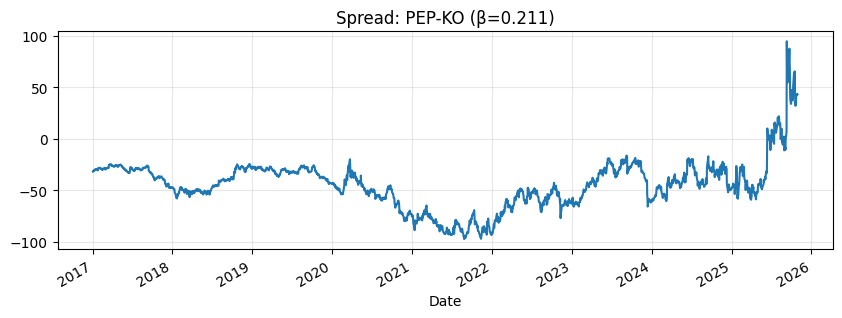

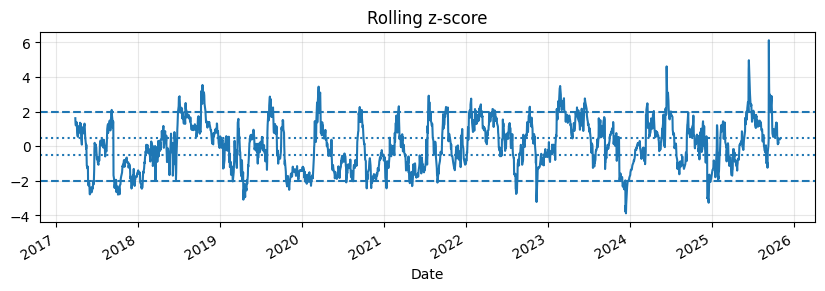

In [15]:
# --- Optional: quick plot for chosen pair ---

fig, ax = plt.subplots(1, 1, figsize=(10, 3.2))
s.plot(ax=ax)
ax.set_title(f"Spread: {A}-{B} (β={beta:.3f})")
ax.grid(True, alpha=0.3)
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(10, 2.8))
z.plot(ax=ax)
ax.axhline( 2.0, ls="--"); ax.axhline(-2.0, ls="--")
ax.axhline( 0.5, ls=":");  ax.axhline(-0.5, ls=":")
ax.set_title("Rolling z-score")
ax.grid(True, alpha=0.3)
plt.show()


Testing pair: PG-KMB
{'AnnReturn': 0.04589040498768049, 'Sharpe': 0.7250341611777821, 'MaxDD': -0.07707111961226565, 'Turnover': 0.03605227579990987}


/tmp/ipykernel_1746731/3139153722.py:5: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  beta = model.params[-1]


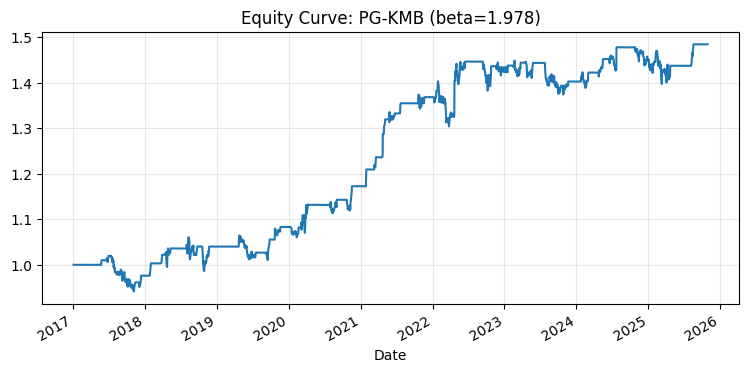

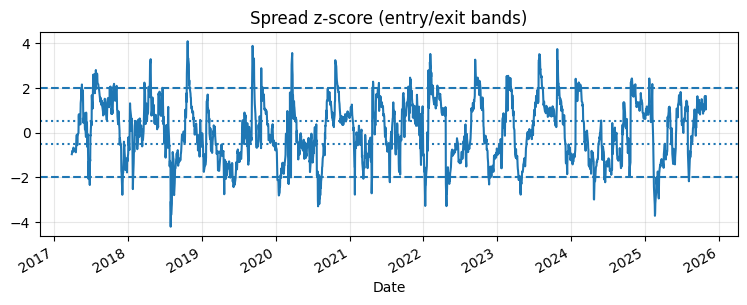

In [17]:
# --- Cell 3: Single-pair pairs-trading backtester ---

@dataclass
class PairsConfig:
    lookback: int = 60
    z_enter: float = 2.0
    z_exit: float = 0.5
    max_gross: float = 1.0         # gross exposure per $1 equity (|leg A| + |leg B|)
    tc_bps: float = 1.0            # one-way transaction cost (bps) applied on notional traded
    slip_bps: float = 0.0          # optional extra slippage per trade (bps)
    beta_const: bool = True        # keep beta fixed from in-sample fit

class PairsBacktester:
    def __init__(self, prices: pd.DataFrame, y_ticker: str, x_ticker: str, cfg: PairsConfig):
        self.cfg = cfg
        self.y = prices[y_ticker].dropna()
        self.x = prices[x_ticker].dropna()
        df = pd.concat([self.y, self.x], axis=1).dropna()
        self.y = df.iloc[:,0]; self.x = df.iloc[:,1]
        self.beta = ols_hedge_ratio(self.y, self.x)
        self.spread = spread_series(self.y, self.x, self.beta)
        self.z = rolling_zscore(self.spread, cfg.lookback)

        self.ret_y = self.y.pct_change()
        self.ret_x = self.x.pct_change()

    def _scale_positions(self, side: float) -> Tuple[pd.Series, pd.Series]:
        """
        side = +1 means LONG spread (buy y, sell beta*x)
        side = -1 means SHORT spread (sell y, buy beta*x)
        We scale legs so that |y| + |beta*x| = max_gross.
        """
        g = self.cfg.max_gross
        k = g / (1.0 + abs(self.beta))
        pos_y = side * k
        pos_x = -side * self.beta * k
        # constant notional (rebalanced when signal flips/flat)
        return (pd.Series(pos_y, index=self.z.index), pd.Series(pos_x, index=self.z.index))

    def run(self) -> Dict[str, Any]:
        z = self.z.copy()

        # Trading rules:
        # ENTER long when z < -z_enter; EXIT when z > -z_exit
        # ENTER short when z >  z_enter; EXIT when z <  z_exit
        long_on  = z < -self.cfg.z_enter
        long_off = z > -self.cfg.z_exit
        short_on = z >  self.cfg.z_enter
        short_off= z <  self.cfg.z_exit

        state = pd.Series(0, index=z.index)       # 0=flat, +1=long spread, -1=short spread
        mode = 0
        for t in z.index:
            if mode == 0:
                if long_on.loc[t]:  mode = +1
                elif short_on.loc[t]: mode = -1
            elif mode == +1:
                if long_off.loc[t]: mode = 0
            elif mode == -1:
                if short_off.loc[t]: mode = 0
            state.loc[t] = mode

        pos_y_c, pos_x_c = self._scale_positions(1.0)  # base magnitudes
        pos_y = pos_y_c * state
        pos_x = pos_x_c * state

        # Realize next-day returns (enter at close, earn next day's move)
        pos_y_shift = pos_y.shift(1).fillna(0)
        pos_x_shift = pos_x.shift(1).fillna(0)

        strat_ret = pos_y_shift * self.ret_y + pos_x_shift * self.ret_x

        # Transaction costs on notional turnover
        traded_notional = (pos_y.diff().abs().fillna(abs(pos_y).fillna(0)) +
                           pos_x.diff().abs().fillna(abs(pos_x).fillna(0)))
        tc = traded_notional * (self.cfg.tc_bps + self.cfg.slip_bps) / 10000.0
        net_ret = strat_ret - tc

        equity = (1 + net_ret.fillna(0)).cumprod()
        out = {
            "net_ret": net_ret,
            "gross_ret": strat_ret,
            "equity": equity,
            "positions": pd.DataFrame({"y": pos_y, "x": pos_x}),
            "state": state,
            "z": z,
            "beta": self.beta
        }

        # Quick metrics
        out["metrics"] = {
            "AnnReturn": float(annualized_return(net_ret)),
            "Sharpe": float(sharpe(net_ret)),
            "MaxDD": float(max_drawdown(equity)),
            "Turnover": float(turnover(out["positions"]))
        }
        return out

# === Example run on the first screened pair (or pick your own) ===
if pair_table.empty:
    print("No pairs passed the screen; relax thresholds or adjust universe.")
else:
    y_t, x_t = pair_table.loc[0, ["y","x"]]
    print(f"Testing pair: {y_t}-{x_t}")
    cfg = PairsConfig(lookback=60, z_enter=2.0, z_exit=0.5, max_gross=1.0, tc_bps=1.0, slip_bps=0.0)
    bt = PairsBacktester(prices, y_t, x_t, cfg)
    res = bt.run()
    print(res["metrics"])

    # Minimal plots (single-figure policy: one chart per cell if you split them)
    fig, ax = plt.subplots(figsize=(9,4))
    res["equity"].plot(ax=ax)
    ax.set_title(f"Equity Curve: {y_t}-{x_t} (beta={bt.beta:.3f})")
    ax.grid(True, alpha=0.3)
    plt.show()

    fig, ax = plt.subplots(figsize=(9,3))
    res["z"].plot(ax=ax)
    ax.axhline(cfg.z_enter, linestyle="--"); ax.axhline(-cfg.z_enter, linestyle="--")
    ax.axhline(cfg.z_exit, linestyle=":");   ax.axhline(-cfg.z_exit, linestyle=":")
    ax.set_title("Spread z-score (entry/exit bands)")
    ax.grid(True, alpha=0.3)
    plt.show()


In [ ]:
# --- Cell 4A (robust patch): Market features + OOS HMM regimes ---

import yfinance as yf
import numpy as np
import pandas as pd
from hmmlearn.hmm import GaussianHMM

def _download_one(t, start="2017-01-01"):
    df = yf.download(t, start=start, auto_adjust=True, progress=False)
    if df is None or df.empty:
        return None
    s = df["Close"].copy() if "Close" in df.columns else df.get("Adj Close", None)
    if s is None or s.empty:
        return None
    s.name = t
    return s

def get_market_series(start="2017-01-01"):
    for t in ["SPY", "^GSPC", "IVV"]:
        s = _download_one(t, start=start)
        if s is not None:
            s = s.copy()
            s.name = "MKT"
            return s
    raise RuntimeError("Could not download a market index (SPY/^GSPC/IVV).")

# Helper: ensure 1-D Series with a name
def as_series(obj, name: str) -> pd.Series:
    if isinstance(obj, pd.Series):
        s = obj.copy()
    elif isinstance(obj, pd.DataFrame):
        # take first column if it's a 1-col frame
        if obj.shape[1] >= 1:
            s = obj.iloc[:, 0].copy()
        else:
            raise ValueError(f"{name}: empty DataFrame cannot be converted to Series.")
    else:
        s = pd.Series(obj)
    s.name = name
    return s

# 1) Market series aligned to your prices
mkt = get_market_series(start=prices.index.min().strftime("%Y-%m-%d"))
mkt = as_series(mkt, "MKT").reindex(prices.index).ffill().dropna()

# 2) Features: daily return, 20d realized vol, 10d momentum
r = as_series(mkt.pct_change(), "ret")
vol20 = as_series(r.rolling(20).std() * np.sqrt(252), "vol20")
mom10 = as_series(mkt.pct_change(10), "mom10")

# Build feature matrix X without using .rename(...)
X = pd.concat([r, vol20, mom10], axis=1).dropna()

# ---- standardization helpers
def _zscore_fit(Xdf):
    mu = Xdf.mean()
    sd = Xdf.std().replace(0, np.nan)
    Z = (Xdf - mu) / sd
    return Z.replace([np.inf, -np.inf], np.nan).dropna(), mu, sd

def _zscore_apply(Xdf, mu, sd):
    Z = (Xdf - mu) / sd
    return Z.replace([np.inf, -np.inf], np.nan)

# 3) Rolling HMM fit to get OOS state at each t using only past data
def rolling_hmm_states(X, train_len=500, n_states=2, random_state=2021, covariance_type="full", n_iter=200):
    idx = X.index
    states = pd.Series(index=idx, dtype="float")
    for t in range(train_len, len(X)):
        X_train = X.iloc[:t].copy()
        Z_train, mu, sd = _zscore_fit(X_train)
        if len(Z_train) < max(50, n_states * 20):
            continue

        model = GaussianHMM(n_components=n_states, covariance_type=covariance_type,
                            n_iter=n_iter, random_state=random_state)
        model.fit(Z_train.values)

        Z_seq = _zscore_apply(X.iloc[:t+1], mu, sd).dropna()
        if len(Z_seq) == 0:
            continue
        st_seq = model.predict(Z_seq.values)

        # ✅ Use label-based assignment (index is datetime)
        states.loc[Z_seq.index[-1]] = int(st_seq[-1])

    return states.astype("Int64")

oos_states = rolling_hmm_states(X, train_len=500, n_states=2)
print("OOS states coverage:", oos_states.notna().mean())

# 4) Identify which state is lower-vol (mean-reverting candidate)
state_vol = X["vol20"].groupby(oos_states).median()
low_vol_state = int(state_vol.sort_values().index[0]) if not state_vol.dropna().empty else 0
print(f"Low-vol state is: {low_vol_state}")

print("State counts:\n", oos_states.value_counts(dropna=False).sort_index())


IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices